<a href="https://colab.research.google.com/github/AlvinManoj05/Parallel_project_Computer_Vision/blob/main/Parallel_Project__computerVision_PneumoniaDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

01_Dataset_Exploration_and_Preprocessing-Ananthika

Import Libraries

In [23]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from google.colab import drive


In [24]:
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
dataset_path = "/content/drive/MyDrive/ICT AI ML/dataset/pneumoniaDetection/xray_dataset_covid19"

print("Dataset exists:", os.path.exists(dataset_path))
print("Available folders:", os.listdir(dataset_path))


Dataset exists: True
Available folders: ['train', 'test', 'single prediction']


In [26]:
#Count the images

classes = ["NORMAL", "PNEUMONIA"]

for split in ["train", "test"]:
    print(f"\n{split.upper()} DATASET")

    for class_name in classes:
        folder = os.path.join(dataset_path, split, class_name)

        images = [
            file for file in os.listdir(folder)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{class_name}: {len(images)} images")



TRAIN DATASET
NORMAL: 74 images
PNEUMONIA: 74 images

TEST DATASET
NORMAL: 20 images
PNEUMONIA: 20 images


Dataset Exploration – Image Visualization

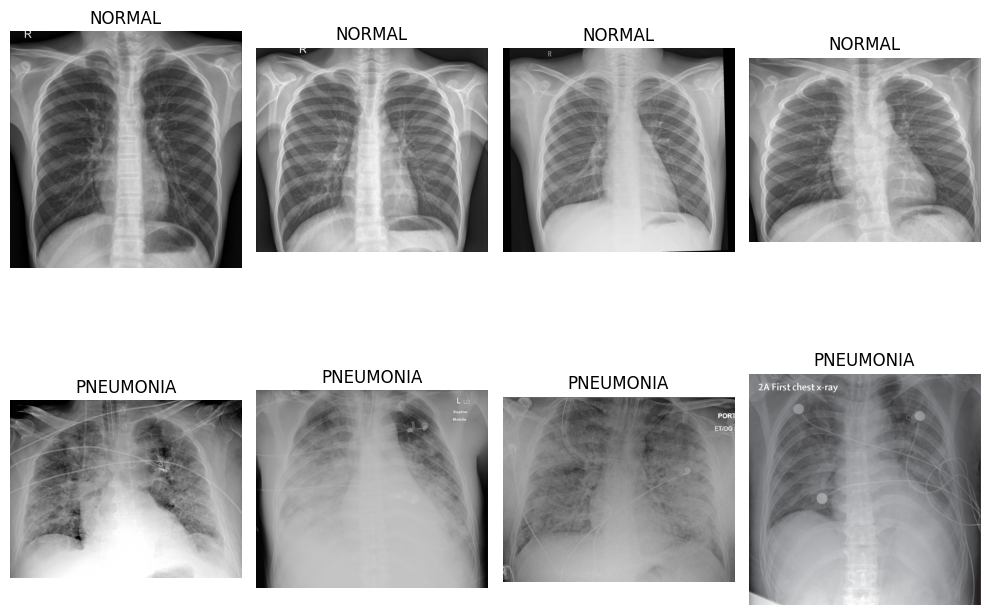

In [27]:
#Display NORMAL and PNEUMONIA images
classes = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, "train", class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    sample_images = random.sample(image_files, min(4, len(image_files)))

    for j, image_name in enumerate(sample_images):
        image_path = os.path.join(folder, image_name)
        image = mpimg.imread(image_path)

        plt.subplot(2, 4, i * 4 + j + 1)
        plt.imshow(image, cmap="gray")
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [28]:
#Image dimensions and formats
image_data = []

classes = ["NORMAL", "PNEUMONIA"]

for class_name in classes:
    folder = os.path.join(dataset_path, "train", class_name)

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        try:
            with Image.open(image_path) as img:
                image_data.append({
                    "Class": class_name,
                    "Filename": filename,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Mode": img.mode
                })

        except Exception as e:
            print("Error:", filename, e)

df = pd.DataFrame(image_data)

print("Total images inspected:", len(df))
print("\nImage dimensions:")
print(df[["Width", "Height"]].describe())

print("\nImage formats:")
print(df["Format"].value_counts())

print("\nImage modes:")
print(df["Mode"].value_counts())


Total images inspected: 148

Image dimensions:
             Width       Height
count   148.000000   148.000000
mean   1697.527027  1385.479730
std     767.623698   693.882888
min     255.000000   237.000000
25%    1246.750000   875.500000
50%    1790.500000  1376.500000
75%    2060.250000  1757.250000
max    4248.000000  4095.000000

Image formats:
Format
JPEG    136
PNG      12
Name: count, dtype: int64

Image modes:
Mode
L       81
RGB     56
RGBA    11
Name: count, dtype: int64


In [29]:
#Check for corrupted images
corrupted_images = []
checked_images = 0

for split in ["train", "test"]:
    for class_name in classes:

        folder = os.path.join(dataset_path, split, class_name)

        for filename in os.listdir(folder):
            image_path = os.path.join(folder, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()

                checked_images += 1

            except Exception:
                corrupted_images.append(image_path)

print("Images checked:", checked_images)
print("Corrupted images:", len(corrupted_images))
print("\nCorrupted file paths:")
print(corrupted_images)


Images checked: 188
Corrupted images: 0

Corrupted file paths:
[]


Train-validation split

In [30]:

image_paths = []
labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, "train", class_name)

    for filename in os.listdir(folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_paths.append(os.path.join(folder, filename))
            labels.append(label)

# Split training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

print("\nTraining class distribution:")
for label, class_name in enumerate(class_names):
    print(class_name, ":", y_train.count(label))

print("\nValidation class distribution:")
for label, class_name in enumerate(class_names):
    print(class_name, ":", y_val.count(label))


Training images: 118
Validation images: 30

Training class distribution:
NORMAL : 59
PNEUMONIA : 59

Validation class distribution:
NORMAL : 15
PNEUMONIA : 15


Image resizing and normalization

In [31]:
IMG_SIZE = 224

def preprocess_images(image_paths):
    images = []

    for path in image_paths:
        img = Image.open(path).convert("L")
        img = img.resize((IMG_SIZE, IMG_SIZE))

        img_array = np.array(img, dtype=np.float32) / 255.0

        images.append(img_array)

    images = np.array(images)
    images = np.expand_dims(images, axis=-1)

    return images

# Preprocess training and validation images
X_train_processed = preprocess_images(X_train)
X_val_processed = preprocess_images(X_val)

# Convert labels into NumPy arrays
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

print("Minimum pixel value:", X_train_processed.min())
print("Maximum pixel value:", X_train_processed.max())


Training shape: (118, 224, 224, 1)
Validation shape: (30, 224, 224, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Visualize preprocessed images

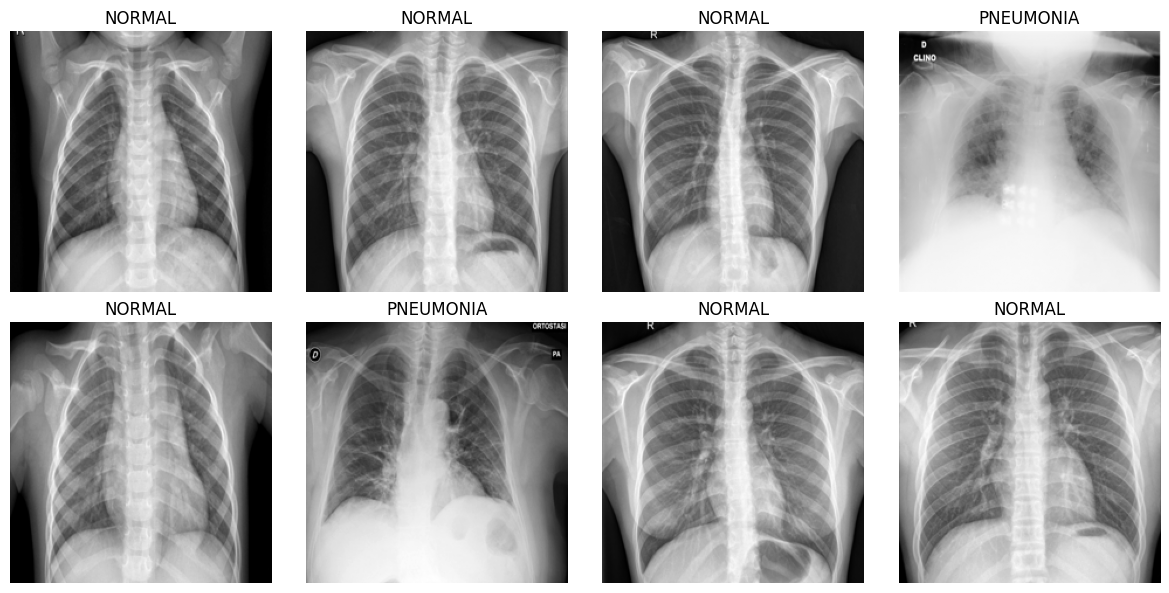

In [32]:
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(X_train_processed[i].squeeze(), cmap="gray")

    label = class_names[int(y_train[i])]
    plt.title(label)

    plt.axis("off")

plt.tight_layout()
plt.show()


Preprocess test images

In [33]:
test_paths = []
test_labels = []

class_names = ["NORMAL", "PNEUMONIA"]

for label, class_name in enumerate(class_names):

    folder = os.path.join(dataset_path, "test", class_name)

    for filename in os.listdir(folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            test_paths.append(os.path.join(folder, filename))
            test_labels.append(label)

# Preprocess test images
X_test_processed = preprocess_images(test_paths)

y_test = np.array(test_labels, dtype=np.float32)

print("Test images:", len(X_test_processed))
print("Test shape:", X_test_processed.shape)

print("\nTest class distribution:")

for i, name in enumerate(class_names):
    print(name, ":", np.sum(y_test == i))


Test images: 40
Test shape: (40, 224, 224, 1)

Test class distribution:
NORMAL : 20
PNEUMONIA : 20


Verify all datasets

In [34]:
print("FINAL DATASET SHAPES")

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nLabel shapes")

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)


FINAL DATASET SHAPES
Training: (118, 224, 224, 1)
Validation: (30, 224, 224, 1)
Testing: (40, 224, 224, 1)

Label shapes
Training labels: (118,)
Validation labels: (30,)
Testing labels: (40,)


Convert images into TensorFlow datasets

In [36]:
BATCH_SIZE = 16

# Training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_processed, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(X_train_processed), seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_processed, y_val)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_processed, y_test)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

print("Training batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))
print("Testing batches:", len(test_dataset))


TensorFlow datasets created successfully!
Training batches: 8
Validation batches: 2
Testing batches: 3


In [37]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())


Image batch shape: (16, 224, 224, 1)
Label batch shape: (16,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [40]:
save_path = "/content/preprocessed_data"
os.makedirs(save_path, exist_ok=True)

np.save(save_path + "/X_train.npy", X_train_processed)
np.save(save_path + "/y_train.npy", y_train)
np.save(save_path + "/X_val.npy", X_val_processed)
np.save(save_path + "/y_val.npy", y_val)
np.save(save_path + "/X_test.npy", X_test_processed)
np.save(save_path + "/y_test.npy", y_test)

print("Saved inside Colab successfully!")

Saved inside Colab successfully!
